# Task 4: DIII-D TGLF database

Builds on the DIII-D shot #128913 equilibrium at 13 radii (r/a = 0.20 to 0.80).

- **Step 1:** run TGLF on the 13 radii, check the fluxes against the provided answers, and plot the flux profile.
- **Step 2:** read the 1000 generated cases (`d3d_mydb_27`) and plot the histograms of the inputs that were varied.

**Requirements:** run from the folder that holds this notebook. `tglf` must be on the PATH only for the run cell in Step 1. If the outputs already exist, that cell skips them.

---

## Step 1: DIII-D profile

In [ ]:
import os, shutil, subprocess, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
# go up to the folder that holds data/ and tglf_dataset.py (next to this notebook, or in src/)
while not any((ROOT / d / "tglf_dataset.py").is_file() for d in (".", "src")) and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT), str(ROOT / "src")]
from tglf_dataset import load_cases

FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)


def run_case(case_dir, dname):
    """Run `tglf -e <dname>` in one case folder (1 thread). Returns (case name, finished?)."""
    with open(case_dir / dname / "tglf.log", "w") as log:
        subprocess.run(["tglf", "-e", dname, "-n", "1"], cwd=case_dir, stdout=log,
                       stderr=subprocess.STDOUT, env=dict(os.environ, OMP_NUM_THREADS="1"))
    return case_dir.name, (case_dir / dname / "out.tglf.gbflux").is_file()


PROFILE = ROOT / "data" / "original_data" / "d3d_profile"   # the 13 radii + d3d_profile_answers.dat
ANSWERS = PROFILE / "d3d_profile_answers.dat"
DNAME = "tglf_sat2"
assert PROFILE.is_dir(), f"{PROFILE} not found - run from the folder that holds this notebook"
print("profile:", PROFILE)

### 1.1 Run TGLF on the 13 radii

One radius at a time so each run can be timed. Radii that already have `out.tglf.gbflux` are skipped.

In [10]:
case_dirs = sorted(p for p in PROFILE.iterdir() if (p / DNAME / "input.tglf").is_file())
print(len(case_dirs), "radii:", [p.name for p in case_dirs])

times = {}
if shutil.which("tglf") is None:
    print("tglf not on PATH - skipping the run (fine if outputs already exist)")
else:
    for d in case_dirs:
        if (d / DNAME / "out.tglf.gbflux").is_file():
            continue
        t0 = time.perf_counter()
        _, ok = run_case(d, DNAME)
        times[d.name] = time.perf_counter() - t0
        print(f"{d.name}: {'OK' if ok else 'FAILED'} in {times[d.name]:.1f} s")

13 radii: ['r020', 'r025', 'r030', 'r035', 'r040', 'r045', 'r050', 'r055', 'r060', 'r065', 'r070', 'r075', 'r080']
tglf not on PATH - skipping the run (fine if outputs already exist)


In [11]:
n_cores = os.cpu_count()
if times:
    sec_per_run = float(np.mean(list(times.values())))
    print(f"mean {sec_per_run:.1f} s per run (single thread), {n_cores} cores")
    for n in (500, 1000):
        print(f"  {n} cases: ~{n * sec_per_run / n_cores / 60:.1f} min on {n_cores} cores")
else:
    print(f"{n_cores} cores; no runs timed this session (all outputs existed or tglf missing)")

16 cores; no runs timed this session (all outputs existed or tglf missing)


### 1.2 Read the fluxes

Read each `out.tglf.gbflux` with the Task 1 code. Species 1 is the electron and species 2 is deuterium, so:

| Flux | Column |
|---|---|
| Gamma_e | `particle_flux_1` |
| Q_e | `energy_flux_1` |
| Q_i | `energy_flux_2` |

In [12]:
df, failures = load_cases(PROFILE)
if len(failures):
    print("FAILED:\n", failures)
res = pd.DataFrame({
    "r_over_a": df["RMIN_LOC"],
    "Q_e": df["energy_flux_1"],
    "Q_i": df["energy_flux_2"],
    "Gamma_e": df["particle_flux_1"],
}).sort_values("r_over_a")
res

,r_over_a,Q_e,Q_i,Gamma_e
case,,,,
r020,0.20,0.38696,1.2641,0.105720
r025,0.25,1.44280,4.5712,0.353010
r030,0.30,3.60190,9.2124,0.815160
r035,0.35,4.96290,11.1260,1.065100
r040,0.40,2.25500,3.6500,0.302310
r045,0.45,2.42750,2.9877,0.219010
r050,0.50,3.22370,3.4251,0.212040
r055,0.55,4.23770,4.0435,0.145240
r060,0.60,5.96160,5.2728,0.034848


### 1.3 Compare with the provided answers

Compare with `d3d_profile_answers.dat`. All 13 radii must agree to at least 3 digits. If any do not, stop and ask the instructors.

In [13]:
ans = pd.read_csv(ANSWERS, comment="#", sep=r"\s+", header=None, nrows=13,
                  names=["dirname", "r_over_a", "Q_e", "Q_i", "Gamma_e"]).set_index("dirname")
mine = res.reindex(ans.index)
rel = ((mine[["Q_e", "Q_i", "Gamma_e"]] - ans[["Q_e", "Q_i", "Gamma_e"]]).abs()
       / ans[["Q_e", "Q_i", "Gamma_e"]].abs())
print("max relative difference per column:\n", rel.max())
print(rel.map("{:.1e}".format))
# 3 digits = 5e-4 relative (answers file has 6 digits, so use a small margin)
assert rel.notna().all().all(), "some radii missing outputs"
assert (rel < 1e-3).all().all(), "STOP: a radius does not match - ask the instructors before going on"
print("\nAll 13 radii agree to at least 3 digits.")

max relative difference per column:
 Q_e        0.0
Q_i        0.0
Gamma_e    0.0
dtype: float64
             Q_e      Q_i  Gamma_e
dirname                           
r020     0.0e+00  0.0e+00  0.0e+00
r025     0.0e+00  0.0e+00  0.0e+00
r030     0.0e+00  0.0e+00  0.0e+00
r035     0.0e+00  0.0e+00  0.0e+00
r040     0.0e+00  0.0e+00  0.0e+00
r045     0.0e+00  0.0e+00  0.0e+00
r050     0.0e+00  0.0e+00  0.0e+00
r055     0.0e+00  0.0e+00  0.0e+00
r060     0.0e+00  0.0e+00  0.0e+00
r065     0.0e+00  0.0e+00  0.0e+00
r070     0.0e+00  0.0e+00  0.0e+00
r075     0.0e+00  0.0e+00  0.0e+00
r080     0.0e+00  0.0e+00  0.0e+00

All 13 radii agree to at least 3 digits.


### 1.4 Flux profile

Q_i, Q_e and Gamma_e against r/a. This is the profile the surrogates will be tested on.

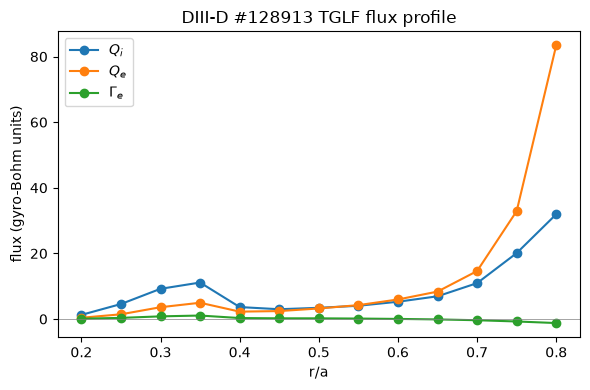

In [14]:
fig, ax = plt.subplots(figsize=(6, 4))
for col, label in [("Q_i", "$Q_i$"), ("Q_e", "$Q_e$"), ("Gamma_e", r"$\Gamma_e$")]:
    ax.plot(res["r_over_a"], res[col], "o-", label=label)
ax.axhline(0, color="gray", lw=0.5)
ax.set_xlabel("r/a"); ax.set_ylabel("flux (gyro-Bohm units)")
ax.set_title("DIII-D #128913 TGLF flux profile"); ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "d3d_profile_fluxes.png", dpi=150)
plt.show()

---

## Step 2: DIII-D database (`d3d_mydb_27`)

### 2.1 Load the cases

Read the TGLF outputs of the 1000 generated cases with the Task 1 code, add the radius and the random factors recorded by `make_db.py`, and save the table.

In [15]:
DB = ROOT / "data" / "original_data" / "d3d_mydb_27" / "data"   # case folders c0001 ... c1000
CASES = ROOT / "data" / "d3d_mydb_27_cases.csv"                  # radius + random factors drawn by make_db.py
TABLE = ROOT / "data" / "d3d_mydb_27_table.csv"

db, db_failures = load_cases(DB, n_jobs=-1, executor="thread")
print(f"{len(db)} cases read, {len(db_failures)} failed")
if len(db_failures):
    display(db_failures)

cases = pd.read_csv(CASES, index_col="case")
factors = [c for c in cases.columns if c.endswith("_factor")] + ["radius"]
db = db.join(cases[factors])
assert db.index.is_unique
db.to_csv(TABLE)
print("wrote", TABLE, db.shape)

884 cases read, 1 failed


,case,reason
0,c0933,missing file: input.tglf.gen


wrote c:\Users\sweek\Downloads\ucsd\ucsd_classes\fa26\dsc180\general-atomics-fusion\data\d3d_mydb_27_table.csv (884, 191)


### 2.2 Input and output histograms

Every input that varies between cases (blue), then the three outputs of interest, Q_e, Q_i and Gamma_e (orange; the energy fluxes on a log axis). The five random-factor inputs (and `RLNS_2`, which equals `RLNS_1`) are ordinary histograms. The geometry inputs are copied from the DIII-D input at each radius, so they only take 13 values and are drawn as one bar per value.

15 varying inputs: ['RMIN_LOC', 'RLNS_1', 'RLNS_2', 'RLTS_1', 'RLTS_2', 'TAUS_2', 'XNUE', 'RMAJ_LOC', 'DRMAJDX_LOC', 'KAPPA_LOC', 'S_KAPPA_LOC', 'DELTA_LOC', 'S_DELTA_LOC', 'Q_LOC', 'Q_PRIME_LOC']


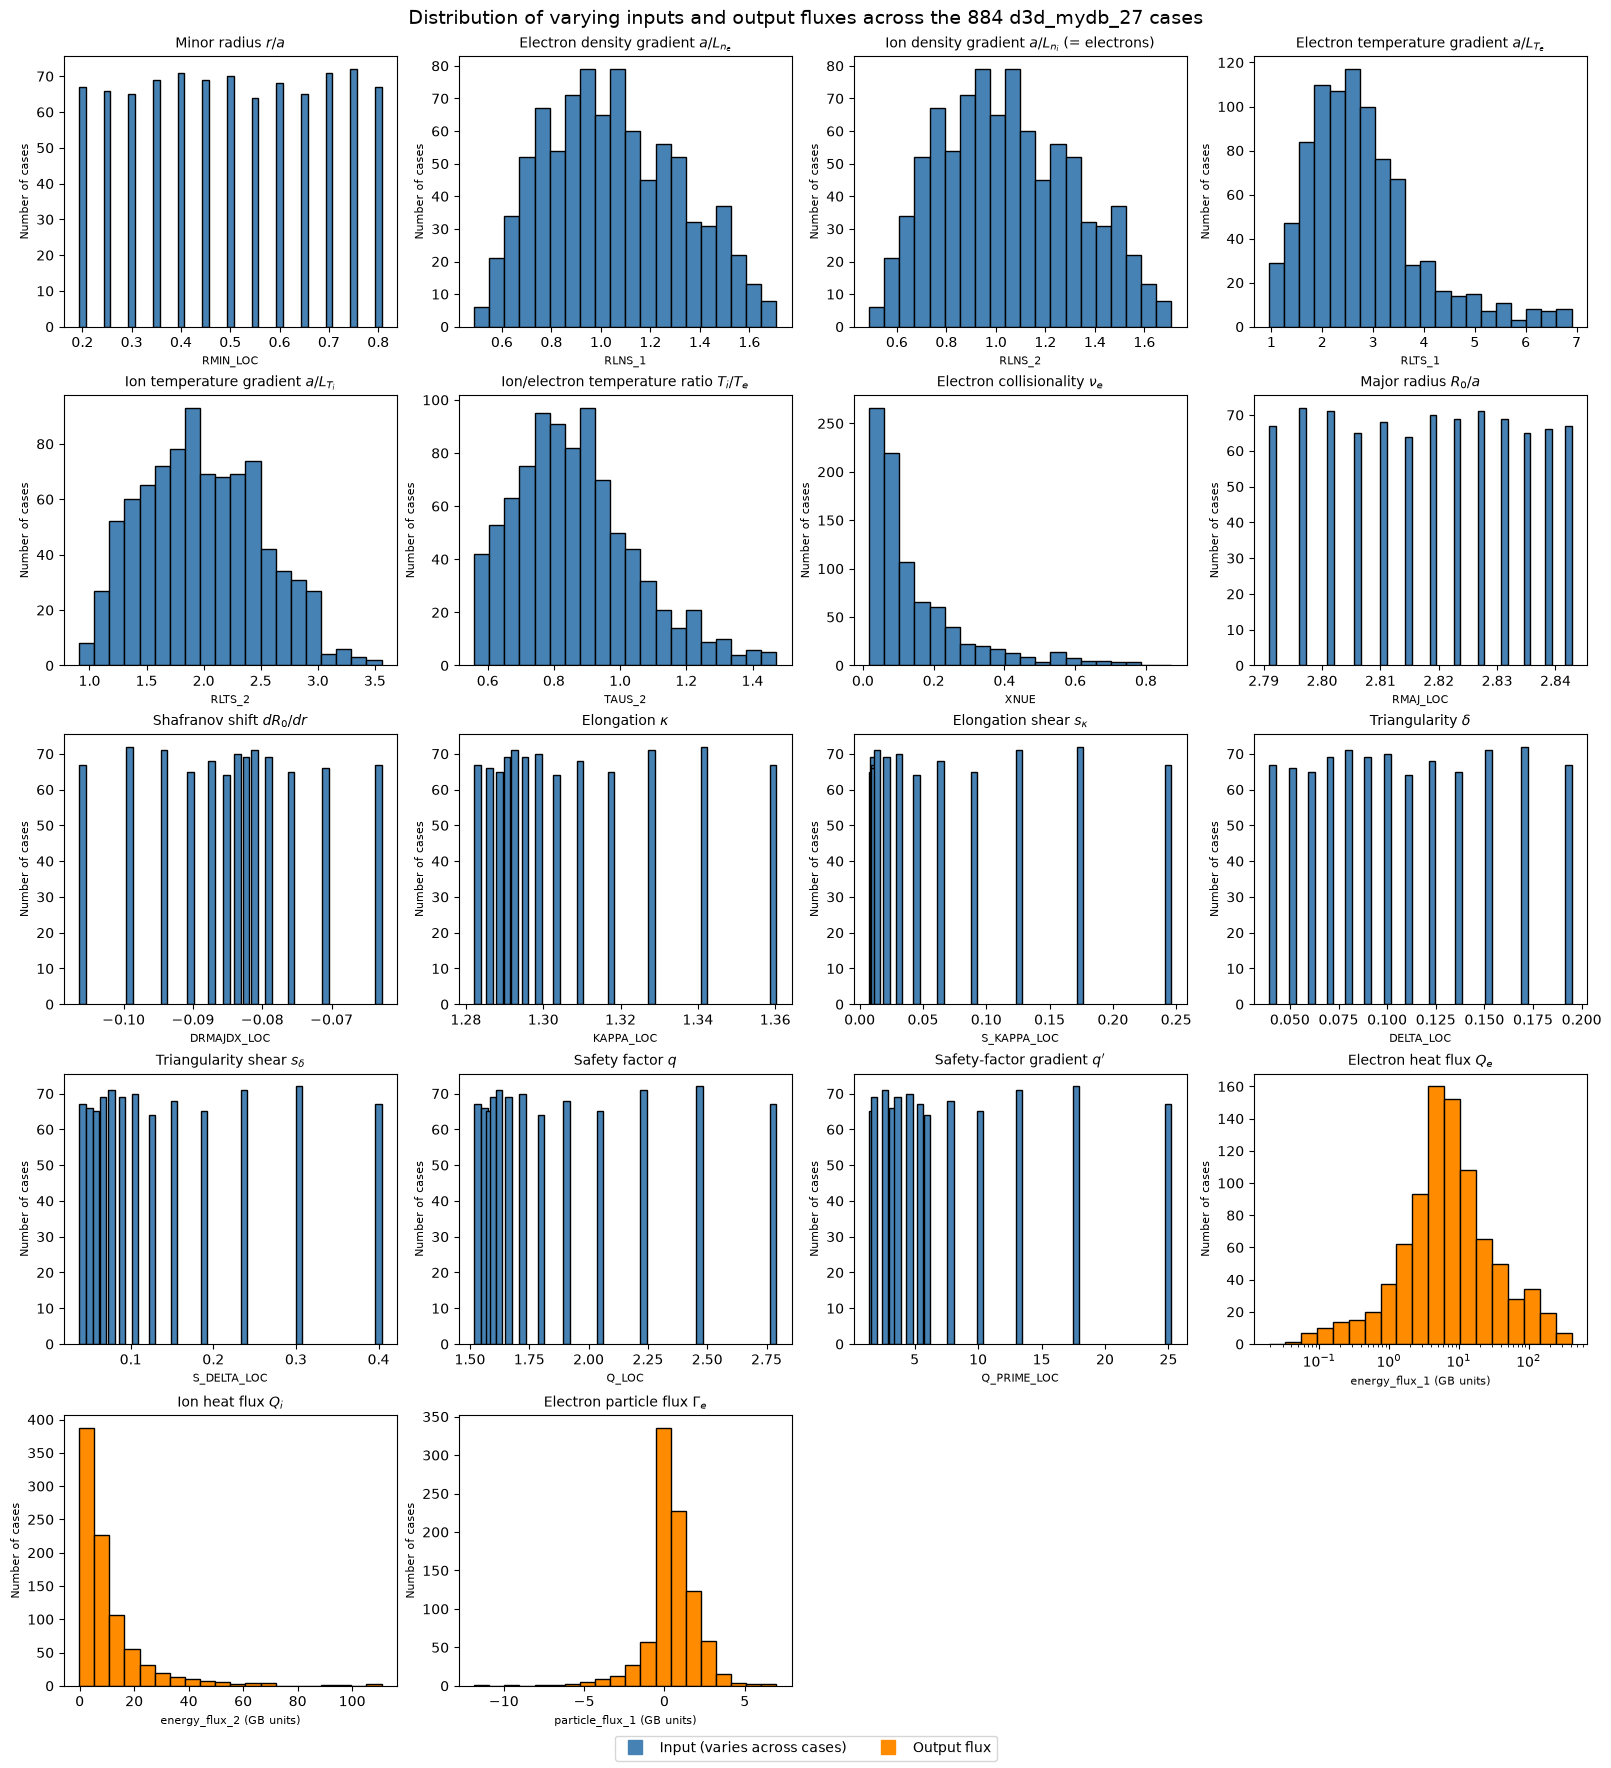

In [18]:
FLUX_PREFIXES = ("particle_flux_", "energy_flux_", "momentum_flux_")
numeric = db.select_dtypes("number")
# every input that changes between cases (the constant ones have nothing to plot); the radius first
inputs = [c for c in numeric.columns
          if not c.startswith(FLUX_PREFIXES) and not c.endswith("_factor") and numeric[c].nunique() > 1]
inputs = ["RMIN_LOC"] + [c for c in inputs if c != "RMIN_LOC"]
print(len(inputs), "varying inputs:", inputs)

X_LABELS = {
    "RMIN_LOC": r"Minor radius $r/a$",
    "RLTS_1": r"Electron temperature gradient $a/L_{T_e}$",
    "RLTS_2": r"Ion temperature gradient $a/L_{T_i}$",
    "RLNS_1": r"Electron density gradient $a/L_{n_e}$",
    "RLNS_2": r"Ion density gradient $a/L_{n_i}$ (= electrons)",
    "TAUS_2": r"Ion/electron temperature ratio $T_i/T_e$",
    "XNUE": r"Electron collisionality $\nu_e$",
    "RMAJ_LOC": r"Major radius $R_0/a$",
    "DRMAJDX_LOC": r"Shafranov shift $dR_0/dr$",
    "KAPPA_LOC": r"Elongation $\kappa$",
    "S_KAPPA_LOC": r"Elongation shear $s_\kappa$",
    "DELTA_LOC": r"Triangularity $\delta$",
    "S_DELTA_LOC": r"Triangularity shear $s_\delta$",
    "Q_LOC": r"Safety factor $q$",
    "Q_PRIME_LOC": r"Safety-factor gradient $q'$",
}
RANDOM = {"RLTS_1", "RLTS_2", "RLNS_1", "RLNS_2", "TAUS_2", "XNUE"}   # drawn with random factors

# the outputs of interest (Task 4): Q_e, Q_i, Gamma_e
outputs = ["energy_flux_1", "energy_flux_2", "particle_flux_1"]
FLUX_NAMES = {
    "energy_flux_1": r"Electron heat flux $Q_e$",
    "energy_flux_2": r"Ion heat flux $Q_i$",
    "particle_flux_1": r"Electron particle flux $\Gamma_e$",
}
cols = inputs + outputs

ncols = 4
nrows = -(-len(cols) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.4 * nrows + 0.6), constrained_layout=True)
for ax, col in zip(axes.flat, cols):
    s = db[col]
    if col in outputs:     # fluxes in orange; energy fluxes on a log axis (as in the SAT3 notebook)
        log_axis = col.startswith("energy_flux") and s.min() > 0
        bins = np.logspace(np.log10(s.min()), np.log10(s.max()), 20) if log_axis else 20
        if log_axis:
            ax.set_xscale("log")
        ax.hist(s, bins=bins, color="darkorange", edgecolor="black")
    elif col in RANDOM:      # continuous: ordinary histogram
        ax.hist(s, bins=20, color="steelblue", edgecolor="black")
    else:                  # one value per radius: one bar per distinct value
        counts = s.value_counts().sort_index()
        ax.bar(counts.index, counts.values, width=(s.max() - s.min()) / 45, color="steelblue", edgecolor="black")
    ax.set_title(FLUX_NAMES.get(col) or X_LABELS.get(col, col)
                 + (" (log scale)" if col in outputs and ax.get_xscale() == "log" else ""), fontsize=10)
    ax.set_xlabel(f"{col} (GB units)" if col in outputs else col, fontsize=8)
    ax.set_ylabel("Number of cases", fontsize=8)
for ax in axes.flat[len(cols):]:
    ax.axis("off")
fig.legend(handles=[
    plt.Line2D([], [], color="steelblue", marker="s", linestyle="", markersize=10, label="Input (varies across cases)"),
    plt.Line2D([], [], color="darkorange", marker="s", linestyle="", markersize=10, label="Output flux"),
], loc="outside lower center", ncol=2)
fig.suptitle(f"Distribution of varying inputs and output fluxes across the {len(db)} d3d_mydb_27 cases", fontsize=14)
fig.savefig(FIG_DIR / "d3d_mydb_27_input_hist.png", dpi=150)
plt.show()